# 02. Línea base

Una CNN sencilla entrenada desde cero con la configuración de `configs/base.toml`. Este notebook no busca un buen número. Busca ver cómo se comporta la red para decidir qué vale la pena cambiar.

Todo el trabajo lo hace el paquete `nubes`. El notebook y la línea de comandos llaman a las mismas funciones. Test no aparece aquí.

## 0. Parámetros

`SEEDS` son las semillas de entrenamiento. El split no cambia con ellas. Una corrida que ya existe en `runs/` se carga en vez de repetirse.

In [2]:
SEEDS = [11, 22, 33] # semillas para repetir el entrenamiento y comparar la variabilidad de los resultados

In [3]:
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

from nubes import eda, figuras
from nubes.config import RunConfig
from nubes.datos import image_root, load_manifest, make_dataset
from nubes.experimento import build_model, load_model, run_seeds
from nubes.inspeccion import feature_maps, receptive_field, shape_trace
from nubes.metricas import group_confusion, symmetric_confusions, top_confusions, within_group_share
from nubes.modelo import count_parameters
from nubes.utilidades import PROJECT_ROOT, pick_device

CONFIGS = PROJECT_ROOT / "configs" # se localiza y carga la configuración de la línea base
base = RunConfig.from_toml(CONFIGS / "base.toml")  # se carga el manifiesto de imágenes y las estadísticas de preparación
manifest, stats = load_manifest(base.data_dir) 
ROOT = image_root(stats)  # se obtiene la raíz de las imágenes y la lista de clases 
CLASSES = stats["classes"] 
device = pick_device(base.device) # se selecciona el dispositivo y se muestra un resumen del experimento
print(device, "|", base.epochs, "épocas |", "semillas", SEEDS)

cpu | 30 épocas | semillas [11, 22, 33]


## 1. Arquitectura y campo receptivo

Cada bloque es `Conv 3x3 → ReLU → MaxPool 2x2`. La tabla de campo receptivo dice qué lado de la imagen de entrada ve una posición del mapa de salida de cada bloque. `fraction` es ese lado como fracción de la imagen.

Después del último bloque la red promedia todo el mapa. Con `head_grid = 1` la posición dentro de la imagen se pierde.

In [4]:
model = build_model(base, len(CLASSES))  # construye la cnn con la configuración y el número de clases
print(f"{count_parameters(model):,} parámetros")  # muestra la cantidad total de parámetros del modelo
display(shape_trace(model, base.image_size))  # muestra las dimensiones de salida de las capas de la red
receptive_field(model, base.image_size)  # calcula el campo receptivo de la cnn

422,731 parámetros


,shape
module,
stages.s1,"(32, 64, 64)"
stages.s2,"(64, 32, 32)"
stages.s3,"(128, 16, 16)"
stages.s4,"(256, 8, 8)"
squeeze,"(256, 1, 1)"
head,"(11,)"


,map_size,rf,fraction,input_pixels_per_cell
stage,,,,
s1,64,4,0.031250,2
s2,32,10,0.078125,4
s3,16,22,0.171875,8
s4,8,46,0.359375,16


## 2. Piloto

Una sola corrida de la línea base con más épocas de las necesarias. Sirve para ver dónde está el mínimo de `val_loss` y fijar un número de épocas común para todos los experimentos.

La decisión se escribe en `docs/PROTOCOLO.md` y se pone en `epochs` de `configs/base.toml` antes de seguir.

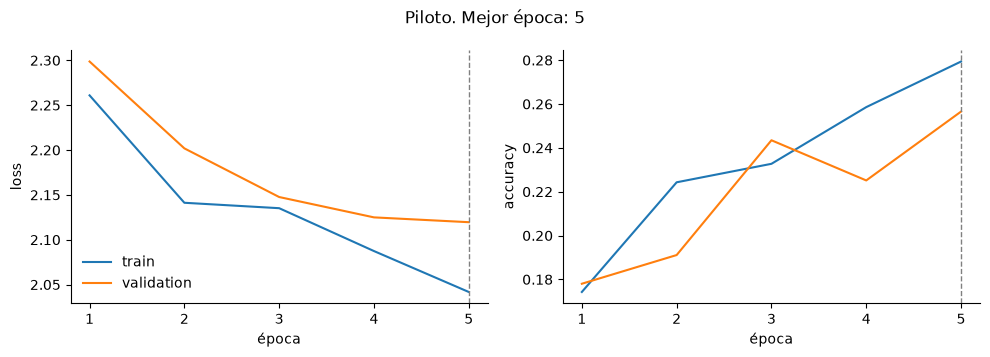

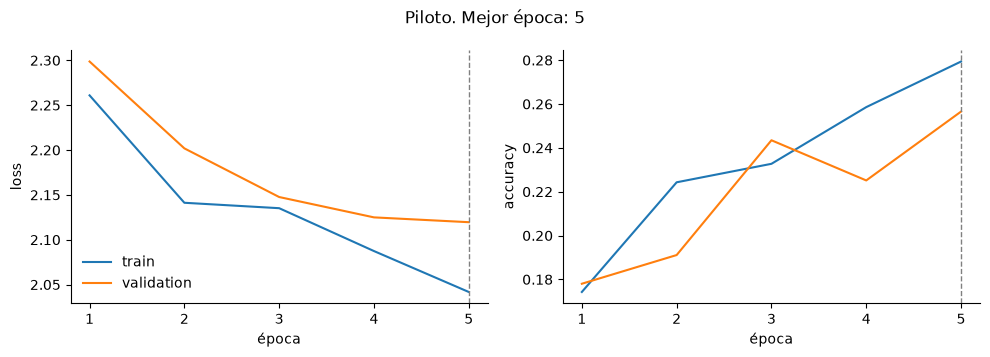

In [5]:
pilot = RunConfig.from_toml(CONFIGS / "piloto.toml")  # carga la configuración del piloto
pilot = pilot.with_changes(experiment="piloto_corto")  # usa otro nombre para conservar los resultados anteriores
pilot_result = run_seeds(pilot, [SEEDS[0]])[0]  # ejecuta cinco épocas con la primera semilla
figuras.plot_history(pilot_result.history, f"Piloto. Mejor época: {pilot_result.best_epoch}")  # grafica el historial y señala la mejor época

In [6]:
history = pilot_result.history.set_index("epoch")  # organiza el historial usando la época como índice
marks = sorted({pilot_result.best_epoch, *range(10, pilot.epochs + 1, 10)})  # selecciona la mejor época y las épocas múltiplos de diez
history.loc[marks, ["train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1"]].round(4)  # muestra las métricas seleccionadas redondeadas a cuatro decimales

,train_loss,train_acc,val_loss,val_acc,val_macro_f1
epoch,,,,,
5,2.0418,0.2794,2.1196,0.2565,0.1921


**Observación:**

Durante las cinco épocas de entrenamiento se observa una disminución progresiva de la pérdida tanto en entrenamiento como en validación. La exactitud de entrenamiento aumenta de 0.174 a 0.279, mientras que la exactitud de validación alcanza un valor de 0.257 en la quinta época. Aunque los resultados muestran una mejora inicial, el modelo todavía presenta una capacidad de clasificación limitada. Además, la pérdida de validación continúa disminuyendo al finalizar el piloto, por lo que no se observa todavía una estabilización clara del aprendizaje.

## 3. Línea base con varias semillas

Misma configuración y mismo split con tres semillas distintas. La dispersión entre semillas es la vara para medir cualquier diferencia entre configuraciones más adelante.

In [ ]:
from nubes.experimento import load_result

result = load_result(base.runs_dir / "linea-base" / "base" / "seed_11")  # carga los resultados guardados
display(result.history.round(4))  # muestra las métricas de las épocas

,epoch,train_loss,train_acc,val_loss,val_acc,val_macro_f1,seconds,best
0,1,2.2609,0.1743,2.2987,0.1780,0.1024,269.5841,1
1,2,2.1412,0.2243,2.2019,0.1911,0.1355,252.0925,1
2,3,2.1352,0.2327,2.1476,0.2435,0.1727,205.2964,1
3,4,2.0874,0.2586,2.1249,0.2251,0.1559,226.2875,1
4,5,2.0418,0.2794,2.1196,0.2565,0.1921,207.4826,1
5,6,2.0385,0.2788,2.0458,0.2775,0.2102,207.5984,1
6,7,1.9996,0.2737,2.0650,0.2644,0.2058,211.7494,0
7,8,1.9752,0.2934,2.0408,0.2958,0.2272,206.7908,1
8,9,1.9705,0.2884,2.0272,0.2696,0.1851,247.5677,1
9,10,1.9356,0.3047,2.0618,0.2801,0.2194,225.9511,0


In [13]:
best = result.history.loc[result.history["best"] == 1]  # selecciona las épocas que mejoraron la pérdida de validación
display(best[["epoch", "train_loss", "val_loss", "train_acc", "val_acc"]])  # muestra las métricas de las mejores épocas

,epoch,train_loss,val_loss,train_acc,val_acc
0,1,2.260936,2.298660,0.174255,0.178010
1,2,2.141216,2.201853,0.224283,0.191099
2,3,2.135169,2.147613,0.232715,0.243455
3,4,2.087388,2.124934,0.258572,0.225131
4,5,2.041777,2.119565,0.279370,0.256545
5,6,2.038543,2.045803,0.278808,0.277487
7,8,1.975157,2.040761,0.293423,0.295812
8,9,1.970463,2.027239,0.288364,0.269634
10,11,1.924397,2.005105,0.304103,0.290576
11,12,1.868046,1.972251,0.328836,0.301047


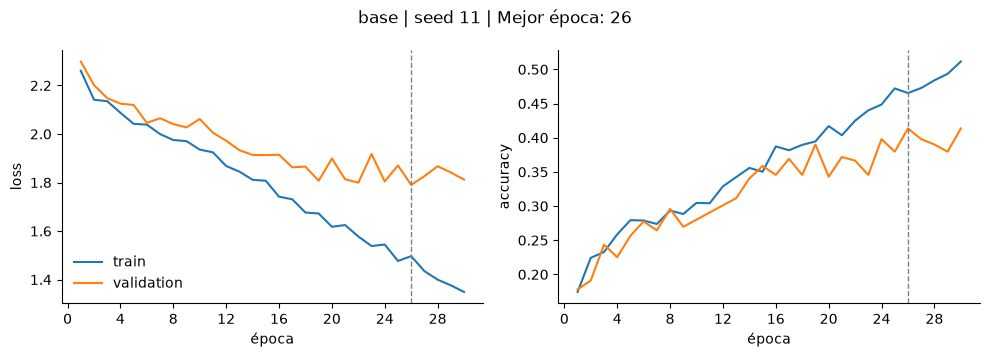

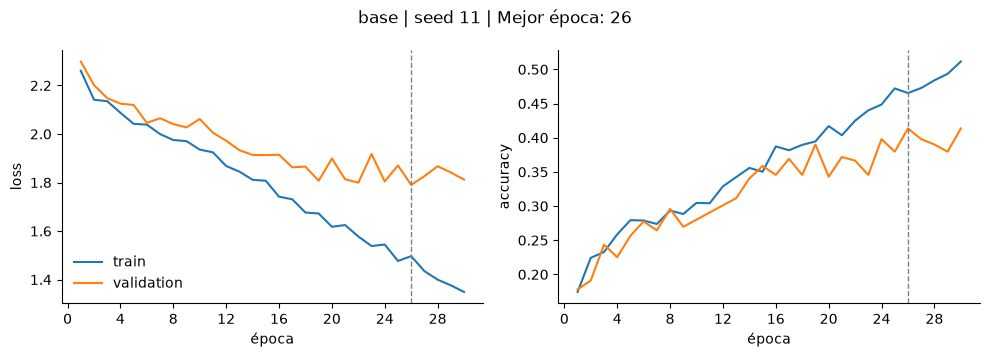

In [14]:
figuras.plot_history(
    result.history,
    f"{base.name} | seed {result.config.seed} | Mejor época: {result.best_epoch}"
)  # grafica el historial de las treinta épocas y señala la mejor época

In [16]:
n_val = sum(result.val.support)  # calcula el número total de imágenes utilizadas en validación
gap = result.gap  # obtiene la diferencia entre la exactitud de entrenamiento y validación

print("imágenes de validación:", n_val)  # muestra el número de imágenes de validación
print("exactitud de validación:", round(result.val.accuracy, 4))  # muestra la exactitud de validación
print("mejor época:", result.best_epoch)  # muestra la época con menor pérdida de validación
print("gap train - val:", round(gap, 4))  # muestra la diferencia entre las exactitudes de entrenamiento y validación

imágenes de validación: 382
exactitud de validación: 0.4136
mejor época: 26
gap train - val: 0.0827


**Observación:**

**Observación de la línea base**

Se observa que la pérdida de entrenamiento disminuye progresivamente durante las 30 épocas, mientras que la pérdida de validación también presenta una tendencia descendente, aunque con fluctuaciones en las últimas épocas. La exactitud de entrenamiento alcanza aproximadamente 0.51, mientras que la de validación llega a 0.41. La mejor época, según la pérdida de validación, es la 26, con una diferencia entre las exactitudes de entrenamiento y validación de 0.0827. Estos resultados indican que la CNN logra aprender características útiles para la clasificación de nubes, aunque su rendimiento todavía es limitado. Además, la separación entre las curvas de entrenamiento y validación sugiere una posible brecha de generalización, por lo que conviene analizar las métricas por clase y la matriz de confusión para identificar qué tipos de nubes presentan mayores dificultades.

## 4. Qué clases se confunden

La matriz suma las tres semillas. El color está normalizado por fila y el número es el conteo.

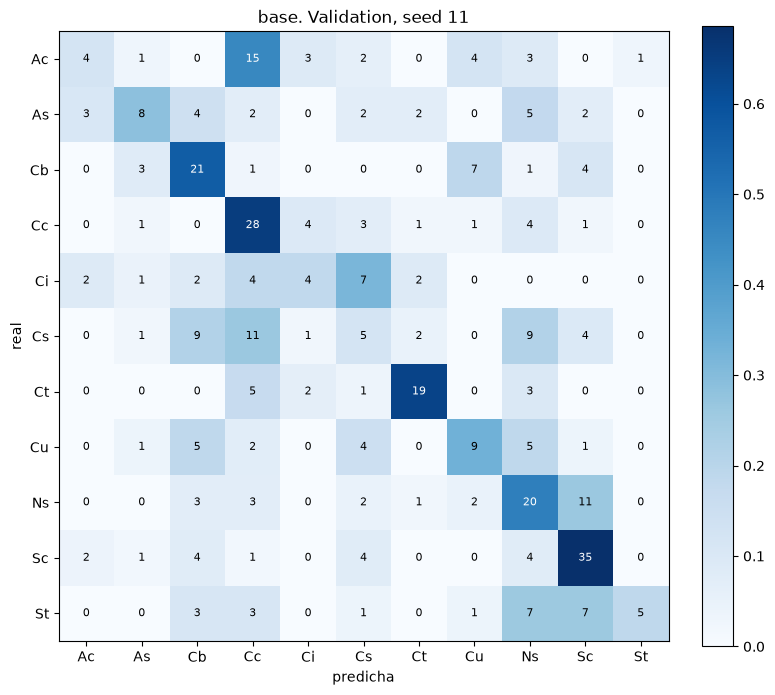

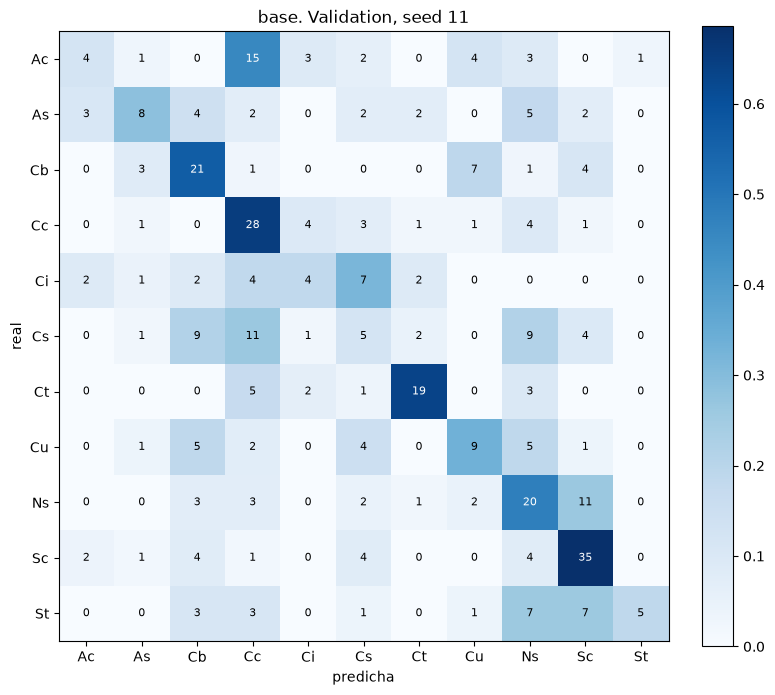

In [18]:
confusion = pd.DataFrame(
    result.val.confusion,
    index=CLASSES,
    columns=CLASSES
)  # construye la matriz de confusión de la corrida recuperada

figuras.plot_matrix(
    confusion,
    CLASSES,
    normalize=True,
    title=f"{base.name}. Validation, seed {result.config.seed}"
)  # grafica la matriz de confusión normalizada para la semilla utilizada

In [20]:
per_class = result.val.per_class(CLASSES)  # obtiene las métricas de validación de cada clase
display(per_class.round(3))  # muestra las métricas redondeadas a tres decimales

display(top_confusions(confusion, CLASSES, k=10))  # muestra las diez confusiones más frecuentes
display(symmetric_confusions(confusion, CLASSES, k=10))  # muestra los pares de clases con más errores en ambos sentidos

,precision,recall,f1,support
Ac,0.364,0.121,0.182,33
As,0.471,0.286,0.356,28
Cb,0.412,0.568,0.477,37
Cc,0.373,0.651,0.475,43
Ci,0.286,0.182,0.222,22
Cs,0.161,0.119,0.137,42
Ct,0.704,0.633,0.667,30
Cu,0.375,0.333,0.353,27
Ns,0.328,0.476,0.388,42
Sc,0.538,0.686,0.603,51


,real,predicha,errores,share
0,Ac,Cc,15,0.454545
1,Ns,Sc,11,0.261905
2,Cs,Cc,11,0.261905
3,Cs,Cb,9,0.214286
4,Cs,Ns,9,0.214286
5,Cb,Cu,7,0.189189
6,St,Ns,7,0.259259
7,Ci,Cs,7,0.318182
8,St,Sc,7,0.259259
9,Ct,Cc,5,0.166667


,par,a→b,b→a,total
0,Ac / Cc,15,0,15
1,Ns / Sc,11,4,15
2,Cc / Cs,3,11,14
3,Cb / Cu,7,5,12
4,Cs / Ns,9,2,11
5,Cb / Cs,0,9,9
6,Ci / Cs,7,1,8
7,Cc / Ci,4,4,8
8,Cs / Sc,4,4,8
9,Cb / Sc,4,4,8


Los errores también se pueden leer por familia. `dentro` es la fracción de los errores que cae entre clases del mismo grupo. `azar` es la fracción de pares de clases distintas que comparten grupo.

In [21]:
info = eda.class_table().loc[CLASSES]  # obtiene la información de las clases de nubes en el orden definido
off_diagonal = ~np.eye(len(CLASSES), dtype=bool)  # crea una máscara para seleccionar las posiciones fuera de la diagonal
rows = {}  # inicializa un diccionario para almacenar los resultados por criterio

for key in ("level", "form"):
    groups = info[key].to_numpy()  # obtiene los grupos según el nivel o la forma de las nubes
    rows[key] = {
        "dentro": within_group_share(confusion, list(groups)),  # calcula la proporción de confusiones entre clases del mismo grupo
        "azar": (groups[:, None] == groups[None])[off_diagonal].mean(),  # calcula la proporción de coincidencias entre grupos al azar
    }
    display(group_confusion(confusion, list(groups)))  # muestra la matriz de confusión agrupada según el criterio analizado

pd.DataFrame(rows).T.round(3)  # presenta el resumen de las proporciones por nivel y forma redondeadas a tres decimales

,alto,bajo,medio,vertical
alto,99,6,21,11
bajo,15,58,20,12
medio,32,20,44,7
vertical,1,11,4,21


,artificial,cirriforme,cumuliforme,estratiforme
artificial,19,2,5,4
cirriforme,2,4,8,8
cumuliforme,1,7,145,38
estratiforme,5,1,68,65


,dentro,azar
level,0.286,0.218
form,0.335,0.291


**Observación:**

La CNN alcanza una exactitud de validación del 41,36 %, con un desempeño variable entre las once clases. Reconoce mejor las clases Cc, Ct y Cb, mientras que presenta dificultades para identificar Ac, Cs y St. La matriz de confusión evidencia errores frecuentes entre Ac y Cc, Ns y Sc, y Cs y Cc. Estos resultados muestran que el modelo logra aprender características útiles, pero aún tiene dificultades para distinguir algunos tipos de nubes, lo que motiva explorar mejoras en la arquitectura y el preprocesamiento.

## 5. Las confusiones de la CNN frente a las del EDA

Se repite el k vecinos del notebook 01 y se compara su matriz de confusión con la de la CNN. La correlación de Spearman se calcula sobre los 55 pares de clases con los errores sumados en ambos sentidos.

Una correlación alta dice que la red se equivoca donde las clases ya se parecían en rasgos globales.

In [22]:
thumbs = eda.load_thumbnails(manifest, ROOT, size=32)  # carga miniaturas de las imágenes con un tamaño de 32 píxeles
_, cm_knn = eda.knn_baseline(eda.simple_features(thumbs).to_numpy(), manifest)  # calcula la matriz de confusión del modelo knn usando características simples de las imágenes
upper = np.triu_indices(len(CLASSES), k=1)  # obtiene los índices de la parte superior de la matriz sin incluir la diagonal


def pair_errors(matrix) -> pd.Series:  # define una función para organizar los errores por pares de clases
    values = np.asarray(matrix)  # convierte la matriz recibida en un arreglo de numpy
    names = [f"{CLASSES[i]} / {CLASSES[j]}" for i, j in zip(*upper, strict=True)]  # crea los nombres de los pares de clases
    return pd.Series((values + values.T)[upper], index=names)  # suma las confusiones en ambas direcciones y las organiza en una serie


both = pd.DataFrame({"cnn": pair_errors(confusion), "knn": pair_errors(cm_knn)})  # reúne los errores por pares de la cnn y del knn en una tabla
print("Spearman:", round(both["cnn"].corr(both["knn"], method="spearman"), 3))  # calcula la correlación de Spearman entre los errores de ambos modelos
both.sort_values("cnn", ascending=False).head(12)  # muestra los doce pares de clases con más errores de la cnn

Spearman: 0.549


,cnn,knn
Ac / Cc,15,15
Ns / Sc,15,9
Cc / Cs,14,12
Cb / Cu,12,9
Cs / Ns,11,2
Cb / Cs,9,4
Cc / Ci,8,3
Cs / Sc,8,9
Ci / Cs,8,0
Cb / Sc,8,17


**Observación:**

La correlación de Spearman de 0,549 indica una concordancia moderada entre los errores de la CNN y el modelo KNN. Ambos modelos coinciden en algunas confusiones frecuentes, como Ac/Cc y Ns/Sc, aunque difieren en otros pares, como Cb/Sc. Esto sugiere que existen dificultades de clasificación compartidas, pero también errores específicos de cada modelo.

## 6. Las imágenes que fallan

`predictions_val.csv` guarda la predicción de cada imagen de validation. Primero se cuenta en cuántas semillas falla cada imagen. Las que fallan en todas son difíciles para esta arquitectura. Las que fallan en una sola son ruido de entrenamiento.

In [24]:
predictions = pd.read_csv(result.run_dir / "predictions_val.csv")  # carga las predicciones de validación guardadas
predictions["error"] = predictions["real"] != predictions["predicha"]  # identifica las imágenes clasificadas incorrectamente

failures = predictions.groupby("path")["error"].sum()  # cuenta si cada imagen fue clasificada incorrectamente
display(
    failures.value_counts()
    .sort_index()
    .rename_axis("semillas que fallan")
    .rename("imágenes")
    .to_frame()
)  # muestra cuántas imágenes fallan y cuántas se clasifican correctamente

,imágenes
semillas que fallan,
0,158
1,224


,imágenes mal clasificadas
real,
St,5
Cc,3
Ac,3
Cu,2
Ns,2
Cb,1
As,1
Cs,1


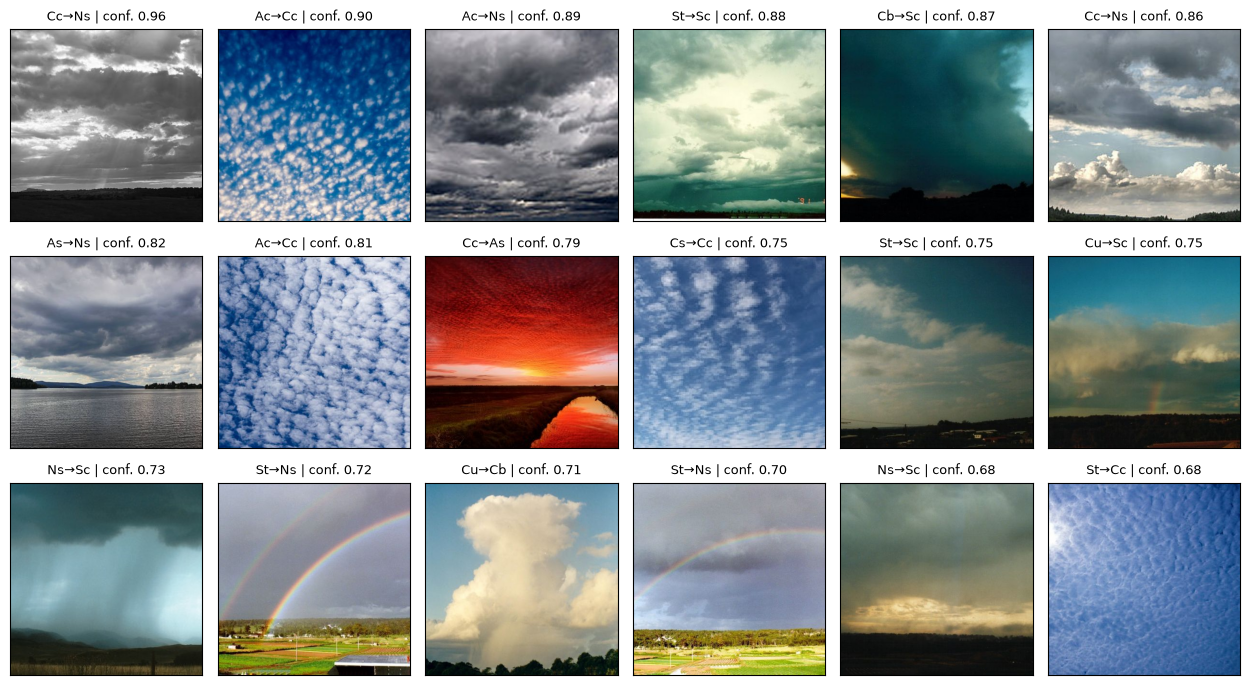

In [26]:
always = failures[failures == 1].index  # identifica las imágenes que fallaron en la única corrida
hard = predictions[predictions["path"].isin(always)].copy()  # selecciona las predicciones de esas imágenes
hard = hard.sort_values("confianza", ascending=False).head(18)  # selecciona hasta 18 imágenes difíciles según la confianza

if len(hard):
    figuras.plot_image_grid(
        [Image.open(ROOT / path).convert("RGB") for path in hard["path"]],  # carga las imágenes seleccionadas
        [f"{r.real}→{r.predicha} | conf. {r.confianza:.2f}" for r in hard.itertuples()],  # etiqueta cada imagen con la clase real, la predicha y la confianza
        ncols=6,  # organiza las imágenes en seis columnas
        cell=2.1,  # establece el tamaño de cada celda de la cuadrícula
    )

display(hard["real"].value_counts().rename("imágenes mal clasificadas").to_frame())  # resume los errores por clase real

**Observación:**

Se observa que 224 imágenes fueron clasificadas incorrectamente en la única corrida analizada, mientras que 158 se clasificaron correctamente. Entre los errores destacan las confusiones entre Ac y Cc, Ns y Sc, y St y Ns. Algunas imágenes presentan una confianza elevada en la predicción equivocada, lo que indica que el modelo no siempre distingue adecuadamente las características visuales de ciertas clases. Estos resultados permiten identificar imágenes difíciles y posibles similitudes visuales entre los tipos de nubes.

## 7. Feature maps después de entrenar

Salida de la ReLU del primer bloque y del último para una imagen de validation.

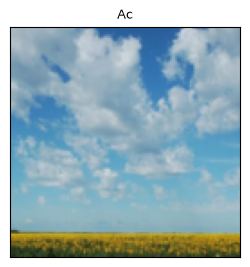

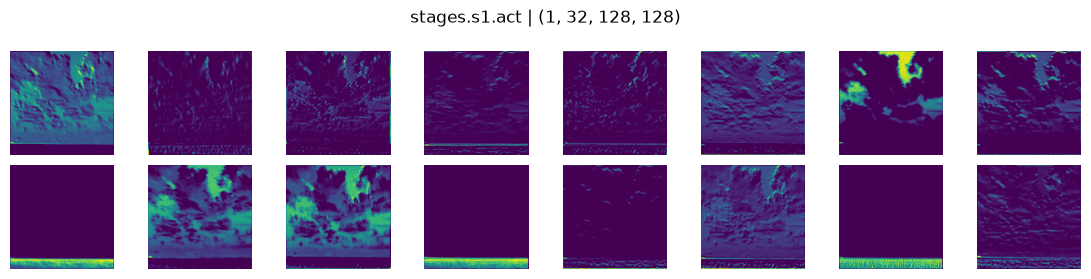

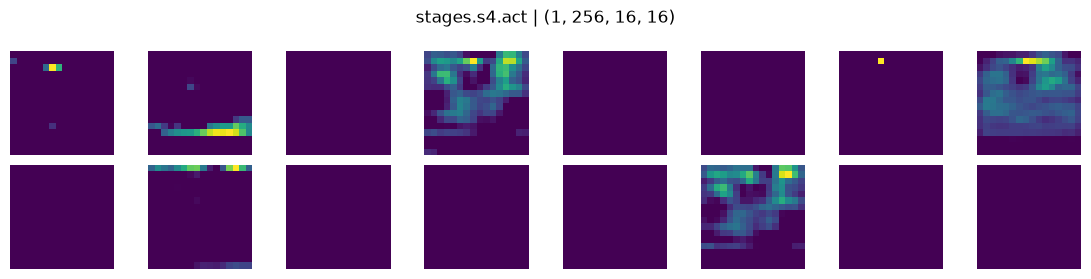

In [28]:
trained, trained_config, _ = load_model(result.run_dir, device)  # carga el modelo entrenado y su configuración
val_dataset = make_dataset(trained_config, "val")  # crea el conjunto de validación
x, y = val_dataset[0]  # obtiene la primera imagen y su etiqueta real

figuras.plot_image_grid(
    [figuras.denormalize(x.unsqueeze(0), stats["mean_train"], stats["std_train"])[0]],
    [CLASSES[y]],  # muestra la imagen con su clase real
    ncols=1,  # organiza la imagen en una sola columna
    cell=2.6,  # establece el tamaño de la celda
)

for layer in ("stages.s1.act", f"stages.s{trained_config.blocks}.act"):
    maps = feature_maps(trained, x.unsqueeze(0), layer)  # extrae los mapas de características de la capa seleccionada
    figuras.plot_feature_maps(maps[0], f"{layer} | {tuple(maps.shape)}")  # visualiza los mapas de características

**Observación**: Los mapas de características muestran que la CNN transforma la imagen original en representaciones progresivamente más abstractas. En el primer bloque se observan patrones distribuidos que conservan detalles de la imagen, mientras que en el último las activaciones se concentran en regiones específicas y algunos mapas presentan poca actividad. Esto evidencia que las capas extraen distintas características visuales, aunque estos resultados no garantizan que sean suficientes para distinguir correctamente todas las clases de nubes.

## 8. Cierre

De aquí sale la hipótesis. En `docs/BITACORA.md` queda escrito:

- qué mostró la línea base y con qué evidencia
- la pregunta del proyecto
- la hipótesis, lo que se espera ver y por qué
- qué variable se va a cambiar y cuáles quedan fijas